In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ── Load both files ───────────────────────────────────────────────────────────
d1 = {k: v for k, v in np.load('outputs/k_saturation/k5_55.npz',   allow_pickle=True).items()}
d2 = {k: v for k, v in np.load('outputs/k_saturation/k50_105.npz', allow_pickle=True).items()}

# Trim d2: remove k=150 and k=165 (already covered by d1)
k2 = d2['k_params'][:, 0]
keep2 = ~np.isin(np.round(k2, 1), [50.0, 55.0])
d2_trim = {key: val[keep2] if (np.ndim(val) > 0 and val.shape[0] == len(k2)) else val
           for key, val in d2.items()}
print(f'd1 samples: {len(d1["t"]):,}')
print(f'd2 trimmed: {keep2.sum():,} / {len(k2):,} (removed k=150,165)')

# Combine — offset d2 time so it continues after d1
t_offset = d1['t'][-1] + (d1['t'][-1] - d1['t'][-2])
combined = {}
for key in d1:
    a, b = d1[key], d2_trim[key]
    if np.ndim(a) == 0:   # scalar metadata → keep from d1
        combined[key] = a
    elif key == 't':
        combined[key] = np.concatenate([a, b + t_offset])
    else:
        combined[key] = np.concatenate([a, b], axis=0)

t      = combined['t']
k_all  = combined['k_params'][:, 0]
goal_x = combined['goal'][:, 0, 0]
force  = combined['force'] * 9.80665e-3   # load cell outputs GRAMS -> convert to Newtons

k_unique_test = sorted([kv for kv in np.unique(np.round(k_all, 1)) if kv != 600.0])
print(f'\nCombined samples: {len(t):,}')
print(f'Test k values ({len(k_unique_test)}): {k_unique_test}')

d1 samples: 442,636
d2 trimmed: 170,391 / 202,167 (removed k=150,165)

Combined samples: 613,027
Test k values (37): [5.0, 7.0, 9.0, 11.0, 13.0, 15.0, 17.0, 19.0, 21.0, 23.0, 25.0, 27.0, 29.0, 31.0, 33.0, 35.0, 37.0, 39.0, 41.0, 43.0, 45.0, 47.0, 49.0, 51.0, 53.0, 55.0, 60.0, 65.0, 70.0, 75.0, 80.0, 85.0, 90.0, 95.0, 100.0, 105.0, 200.0]


In [3]:
# ── Extract MOVING_OUT intervals for each k ───────────────────────────────────
# Strategy: within each contiguous segment at k=test_k,
# the ref goes 0→-25cm (MOVING_OUT) then -25cm→0 (MOVING_BACK).
# Split at the minimum of goal_x to isolate only the outward sweep.

segments = {}   # k_value → list of (goal_x_out, force_out) arrays

k_rounded = np.round(k_all, 1)

for kv in k_unique_test:
    in_seg = k_rounded == kv
    # find contiguous blocks
    changes = np.diff(in_seg.astype(int))
    starts  = np.where(changes == 1)[0] + 1
    ends    = np.where(changes == -1)[0] + 1
    if in_seg[0]:  starts = np.concatenate([[0], starts])
    if in_seg[-1]: ends   = np.concatenate([ends, [len(in_seg)]])

    segs_kv = []
    for s, e in zip(starts, ends):
        gx = goal_x[s:e]
        f  = force[s:e]
        if len(gx) < 5:
            continue
        # find where goal_x is minimum (end of outward sweep)
        split = int(np.argmin(gx))
        if split < 3:   # degenerate segment, skip
            continue
        # keep only the outward portion (0 → -25cm)
        segs_kv.append((gx[:split+1], f[:split+1]))
    segments[kv] = segs_kv

valid_k = [kv for kv in k_unique_test if segments[kv]]
print(f'Extracted segments for {len(valid_k)} k values')
for kv in valid_k:
    print(f'  k={kv:.0f}: {len(segments[kv])} sweep(s)')

Extracted segments for 36 k values
  k=5: 1 sweep(s)
  k=7: 1 sweep(s)
  k=9: 1 sweep(s)
  k=11: 1 sweep(s)
  k=13: 1 sweep(s)
  k=15: 1 sweep(s)
  k=17: 1 sweep(s)
  k=19: 1 sweep(s)
  k=21: 1 sweep(s)
  k=23: 1 sweep(s)
  k=25: 1 sweep(s)
  k=27: 1 sweep(s)
  k=29: 1 sweep(s)
  k=31: 1 sweep(s)
  k=33: 1 sweep(s)
  k=35: 1 sweep(s)
  k=37: 1 sweep(s)
  k=39: 1 sweep(s)
  k=41: 1 sweep(s)
  k=43: 1 sweep(s)
  k=45: 1 sweep(s)
  k=47: 1 sweep(s)
  k=49: 1 sweep(s)
  k=51: 1 sweep(s)
  k=53: 1 sweep(s)
  k=55: 1 sweep(s)
  k=60: 1 sweep(s)
  k=65: 1 sweep(s)
  k=70: 1 sweep(s)
  k=75: 1 sweep(s)
  k=80: 1 sweep(s)
  k=85: 1 sweep(s)
  k=90: 1 sweep(s)
  k=95: 1 sweep(s)
  k=100: 1 sweep(s)
  k=105: 1 sweep(s)


/tmp/ipykernel_15260/544933425.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('coolwarm')


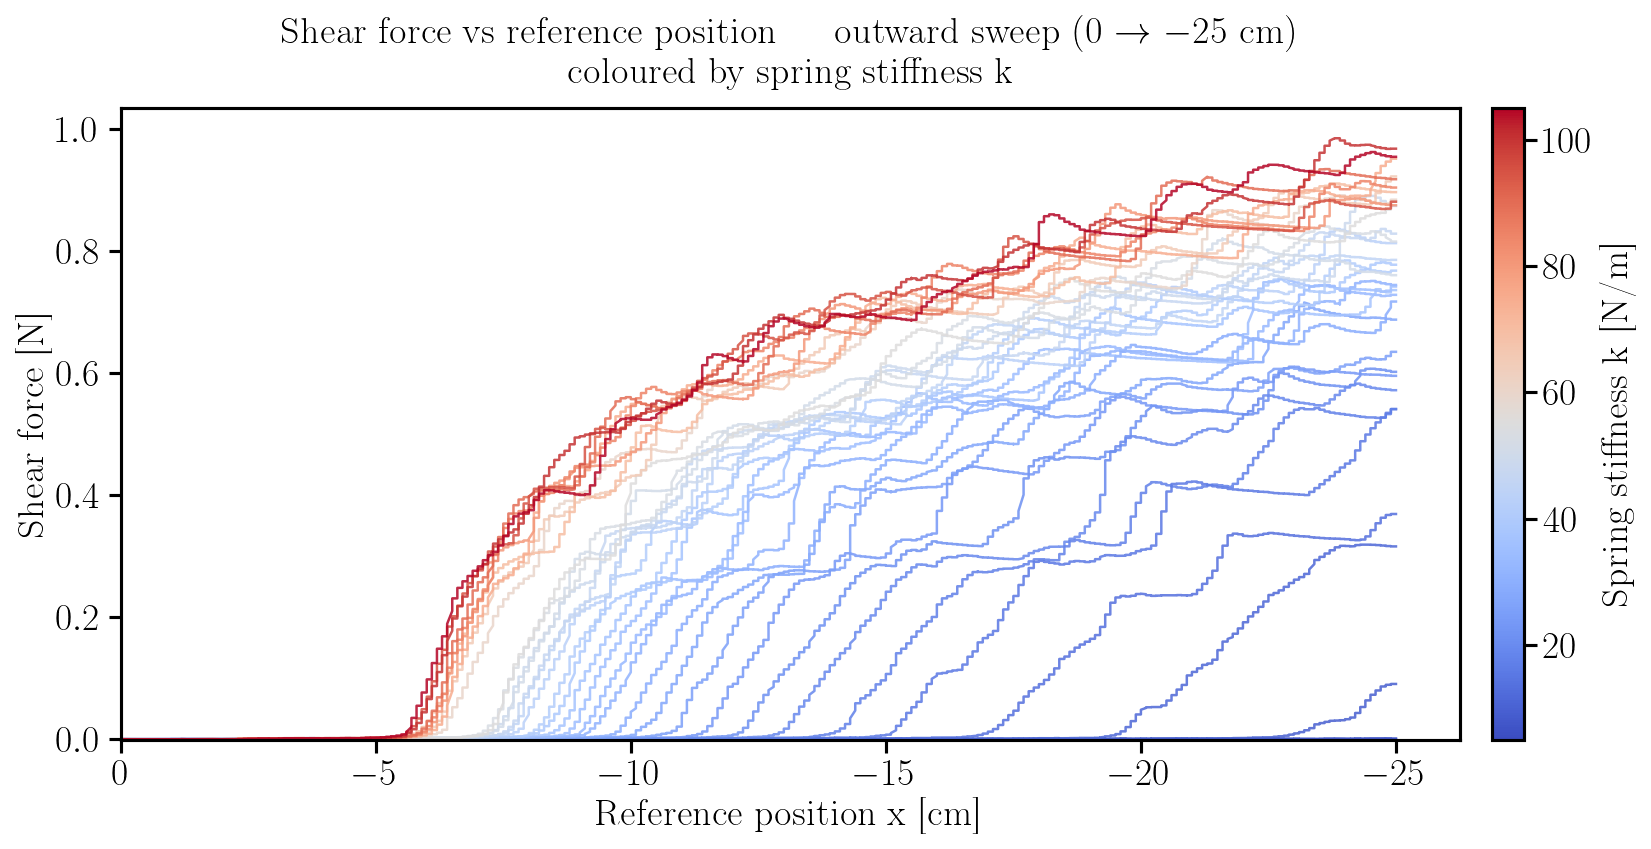

[OK] Saved -> outputs/k_saturation/force_vs_pos_by_k.pdf


In [4]:
# ── Plot: shear force vs ref position, coloured by k ─────────────────────────
# Colormap: cold (blue) for low k → hot (red) for high k

norm   = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap   = cm.get_cmap('coolwarm')

fig, ax = plt.subplots(figsize=(12, 6))

all_gx_cm, all_f = [], []
for kv in valid_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        label = f'k={kv:.0f}' if idx == 0 else None
        ax.plot(gx * 100, f, color=color, linewidth=1.2,
                alpha=0.85, label=label)
        all_gx_cm.append(gx * 100)
        all_f.append(f)
all_gx_cm = np.concatenate(all_gx_cm)
all_f = np.concatenate(all_f)

# Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness k [N/m]')

ax.set_xlabel('Reference position x [cm]')
ax.set_ylabel('Shear force [N]')
ax.set_title('Shear force vs reference position — outward sweep (0 → −25 cm)\n'
             'coloured by spring stiffness k')
ax.grid(GRID)
# Anchor at x=0 (sweep start) with 0 on the left; data goes negative (outward
# sweep to -25cm), so set_xlim(left=0, right=<negative>) both anchors the
# origin and reproduces the desired 0-on-left / -25-on-right orientation
# without a separate invert_xaxis() call.
ax.set_xlim(0, all_gx_cm.min() * 1.05)
ax.set_ylim(min(0, all_f.min() * 1.05), all_f.max() * 1.05)

plt.tight_layout()
plt.savefig('outputs/k_saturation/force_vs_pos_by_k.pdf')
plt.show()
print('[OK] Saved -> outputs/k_saturation/force_vs_pos_by_k.pdf')

/tmp/ipykernel_15260/155916252.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('coolwarm')


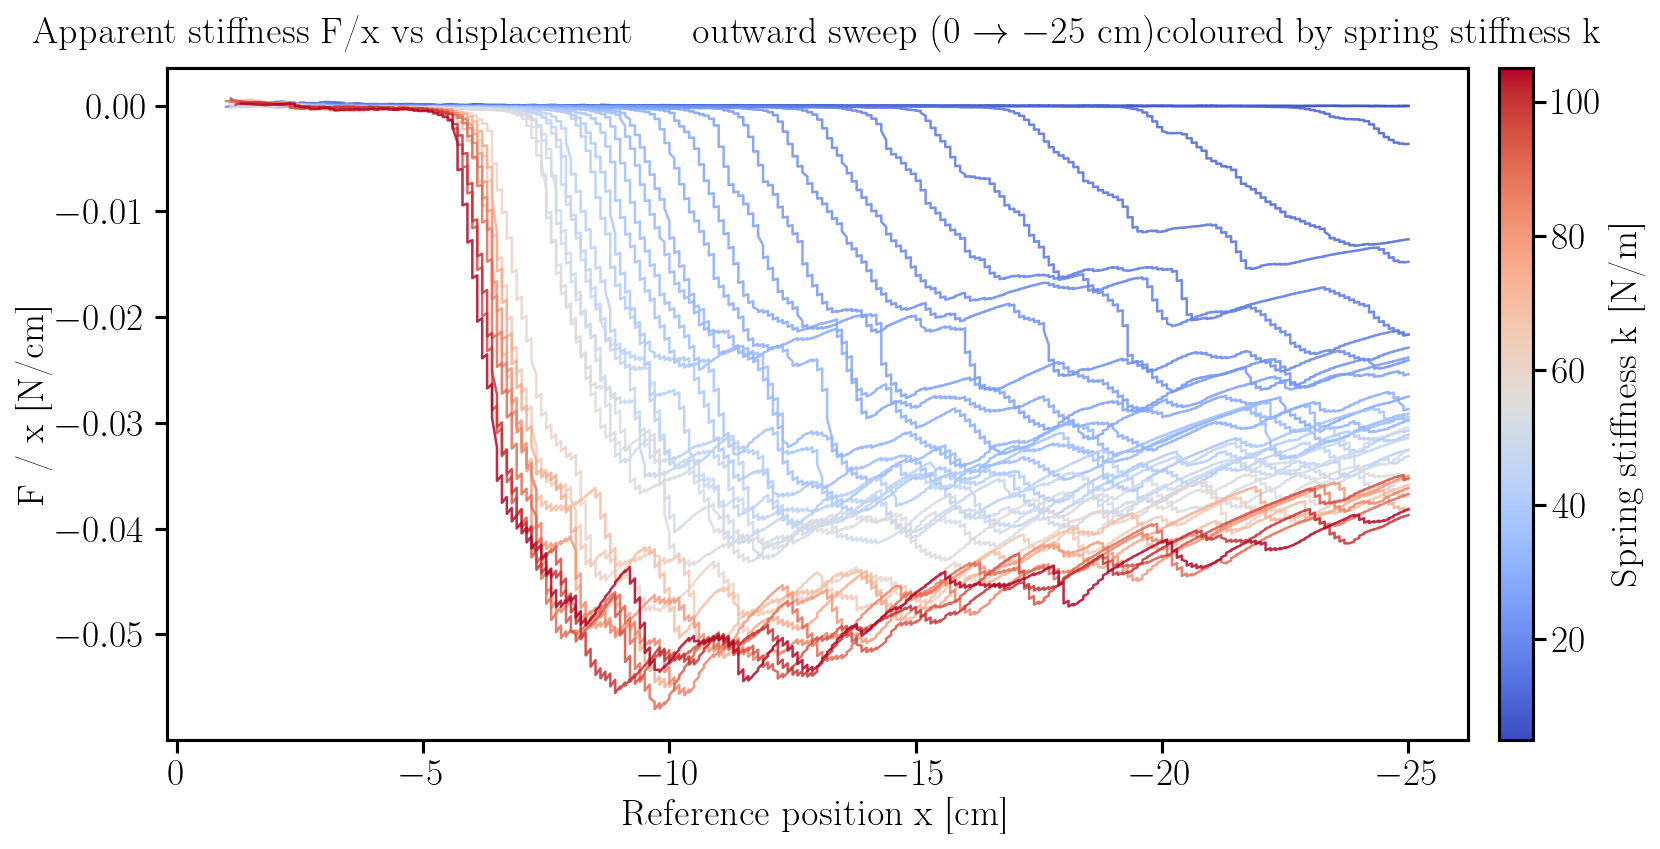

[OK] Saved -> outputs/k_saturation/stiffness_vs_pos_by_k.pdf


In [5]:
# ── Plot: F/x vs x (apparent stiffness) coloured by k ────────────────────────
# Skip points where |x| < X_MIN_CM to avoid division-by-zero near origin
X_MIN_CM = 0.5   # [cm]  ignore first 0.5 cm

norm = mcolors.Normalize(vmin=min(valid_k), vmax=max(valid_k))
cmap = cm.get_cmap('coolwarm')

fig, ax = plt.subplots(figsize=(12, 6))

for kv in valid_k:
    color = cmap(norm(kv))
    for idx, (gx, f) in enumerate(segments[kv]):
        x_cm = gx * 100          # convert to cm
        mask = np.abs(x_cm) >= X_MIN_CM
        xm, fm = x_cm[mask], f[mask]
        if len(xm) < 2:
            continue
        ratio = fm / xm           # F/x  [N/cm]
        label = f'k={kv:.0f}' if idx == 0 else None
        ax.plot(xm, ratio, color=color, linewidth=1.2, alpha=0.85, label=label)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness k [N/m]')

ax.set_xlabel('Reference position x [cm]')
ax.set_ylabel('F / x  [N/cm]')
ax.set_title('Apparent stiffness F/x vs displacement — outward sweep (0 → −25 cm)'
             'coloured by spring stiffness k')
ax.grid(GRID)
ax.invert_xaxis()

plt.tight_layout()
plt.savefig('outputs/k_saturation/stiffness_vs_pos_by_k.pdf')
plt.show()
print('[OK] Saved -> outputs/k_saturation/stiffness_vs_pos_by_k.pdf')

Common integration window: T = 47.92 s  (identical bounds for every k)


/tmp/ipykernel_15260/1069085874.py:44: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('coolwarm')


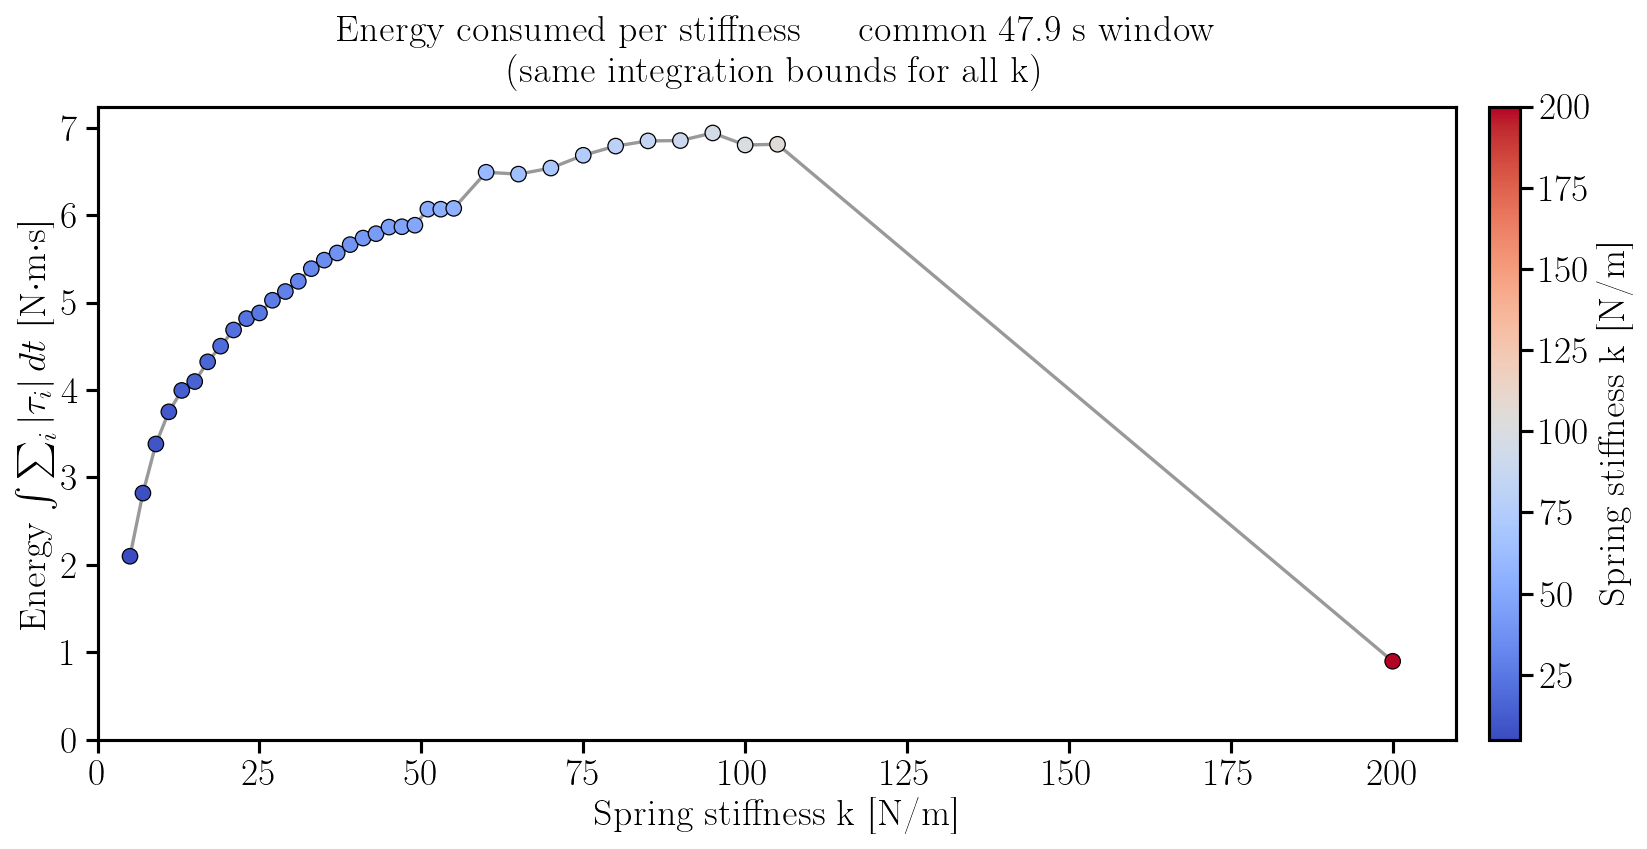


Energy range: 0.9 (k=200) → 6.9 (k=95)  N·m·s


In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# ENERGY CONSUMED vs k  —  integral of sum|tau| over a COMMON time window
# (same integration bounds for every k so the comparison is fair)
# Method matches Surface_tracking: E = ∫ Σ_i |tau_i(t)| dt   (trapezoidal rule)
# ═══════════════════════════════════════════════════════════════════════════════
def trapz(y, x):
    """Trapezoidal integral ∫ y dx (same result as scipy.integrate.trapezoid)."""
    return float(np.sum((y[:-1] + y[1:]) * np.diff(x) / 2.0))

tau_all = combined['tau']          # (n, 9) commanded motor torques

# ── 1. Per-k contiguous block (the full push-out + hold + return at that k) ───
blocks = {}   # k → (start_idx, end_idx)
for kv in k_unique_test:
    in_seg = k_rounded == kv
    ch = np.diff(in_seg.astype(int))
    st = np.where(ch == 1)[0] + 1
    en = np.where(ch == -1)[0] + 1
    if in_seg[0]:  st = np.r_[0, st]
    if in_seg[-1]: en = np.r_[en, len(in_seg)]
    if len(st) == 0:
        continue
    # keep the longest block (the main sweep) for this k
    j = int(np.argmax([t[e - 1] - t[s] for s, e in zip(st, en)]))
    blocks[kv] = (int(st[j]), int(en[j]))

# ── 2. Common integration window = shortest block duration across all k ───────
T_window = min(t[e - 1] - t[s] for (s, e) in blocks.values())
print(f"Common integration window: T = {T_window:.2f} s  (identical bounds for every k)")

# ── 3. Energy per k: integrate Σ|tau| over [t_start, t_start + T_window] ──────
energy_k = {}
for kv, (s, e) in blocks.items():
    t_seg   = t[s:e] - t[s]                       # elapsed time from block start
    w       = t_seg <= T_window                   # same elapsed-time window for all k
    tau_mag = np.sum(np.abs(tau_all[s:e][w]), axis=1)   # Σ_i |tau_i|
    energy_k[kv] = trapz(tau_mag, t_seg[w])

ks   = np.array(sorted(energy_k))
en   = np.array([energy_k[kv] for kv in ks])

# ── 4. Line plot: energy vs k (markers coloured by k, matching the notebook) ──
norm = mcolors.Normalize(vmin=ks.min(), vmax=ks.max())
cmap = cm.get_cmap('coolwarm')

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(ks, en, '-', color='0.6', linewidth=1.6, zorder=1)
ax.scatter(ks, en, c=cmap(norm(ks)), s=55, edgecolor='k', linewidth=0.6, zorder=3)

sm = cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring stiffness k [N/m]')

ax.set_xlabel('Spring stiffness k [N/m]')
ax.set_ylabel(r'Energy  $\int \sum_i |\tau_i|\,dt$   [N·m·s]')
ax.set_xlim(0, None)
ax.set_ylim(0, None)
ax.set_title(f'Energy consumed per stiffness — common {T_window:.1f} s window\n'
             '(same integration bounds for all k)')
ax.grid(GRID)

plt.tight_layout()
plt.savefig('outputs/k_saturation/energy_vs_k.pdf')
plt.show()

print(f"\nEnergy range: {en.min():.1f} (k={ks[en.argmin()]:.0f}) "
      f"→ {en.max():.1f} (k={ks[en.argmax()]:.0f})  N·m·s")


/tmp/ipykernel_15260/1616170847.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_h = cm.get_cmap('plasma', len(high_k))


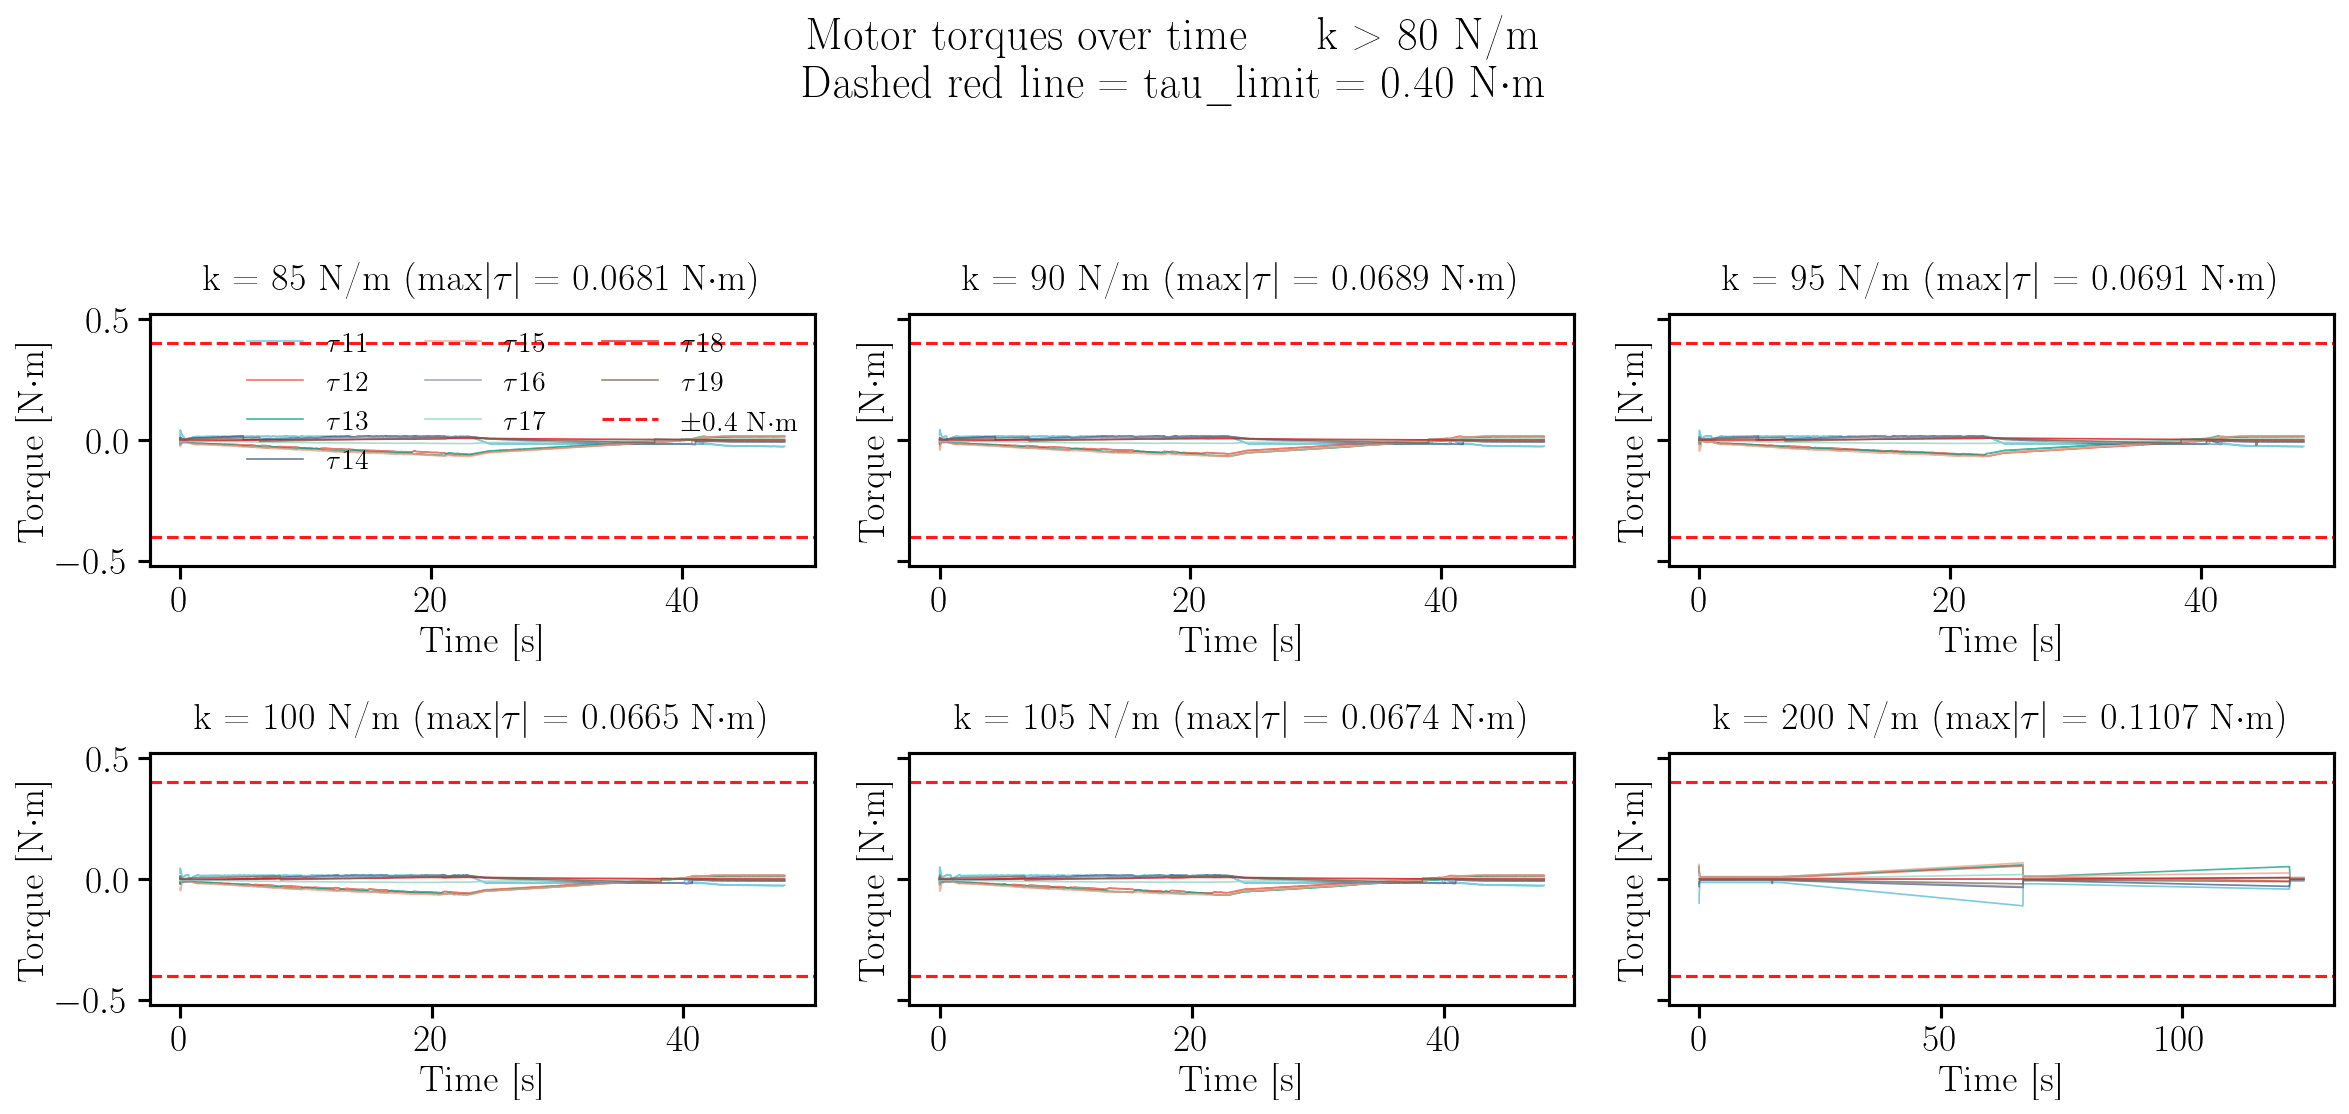

tau_limit = 0.4 N·m
  k=85:  max|τ| = 0.0681 N·m  (17.0% of limit)  → NOT saturated
  k=90:  max|τ| = 0.0689 N·m  (17.2% of limit)  → NOT saturated
  k=95:  max|τ| = 0.0691 N·m  (17.3% of limit)  → NOT saturated
  k=100:  max|τ| = 0.0665 N·m  (16.6% of limit)  → NOT saturated
  k=105:  max|τ| = 0.0674 N·m  (16.9% of limit)  → NOT saturated
  k=200:  max|τ| = 0.1107 N·m  (27.7% of limit)  → NOT saturated


In [7]:
# ── Torque evolution over time for k > 240 (verify tau_limit = 0.4 N·m) ─────
TAU_LIMIT = float(combined['tau_limit'].flat[0])   # from saved config
tau_all   = combined['tau']                        # (n, 9)

high_k = sorted([kv for kv in k_unique_test if kv > 80])
cmap_h = cm.get_cmap('plasma', len(high_k))

fig, axes = plt.subplots(3, 3, figsize=(16, 10), sharex=False, sharey=True)
fig.suptitle(
    f'Motor torques over time — k > 80 N/m\n'
    f'Dashed red line = tau_limit = {TAU_LIMIT:.2f} N·m'
)

motor_labels = [f'τ{i+11}' for i in range(9)]

for ax_idx, kv in enumerate(high_k):
    ax = axes.flat[ax_idx]
    s, e = blocks[kv]
    t_seg = t[s:e] - t[s]          # elapsed time [s]
    tau_k = tau_all[s:e]            # (m, 9)

    for m in range(9):
        ax.plot(t_seg, tau_k[:, m], linewidth=0.8, alpha=0.75,
                label=motor_labels[m])

    # Torque limit lines
    ax.axhline( TAU_LIMIT, color='red', linestyle='--', linewidth=1.5, alpha=0.9,
                label=f'±{TAU_LIMIT} N·m' if ax_idx == 0 else None)
    ax.axhline(-TAU_LIMIT, color='red', linestyle='--', linewidth=1.5, alpha=0.9)

    ax.set_title(f'k = {kv:.0f} N/m  (max|τ| = {np.abs(tau_k).max():.4f} N·m)')
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Torque [N·m]')
    ax.grid(GRID)
    ax.set_ylim(-TAU_LIMIT * 1.3, TAU_LIMIT * 1.3)

# hide unused axes
for ax_idx in range(len(high_k), 9):
    axes.flat[ax_idx].set_visible(False)

# shared legend on first subplot
axes.flat[0].legend(ncol=3, loc='upper right')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('outputs/k_saturation/tau_high_k.pdf')
plt.show()

print(f"tau_limit = {TAU_LIMIT} N·m")
for kv in high_k:
    s, e = blocks[kv]
    m = np.abs(tau_all[s:e]).max()
    pct = 100 * m / TAU_LIMIT
    print(f"  k={kv:.0f}:  max|τ| = {m:.4f} N·m  ({pct:.1f}% of limit)  → {'SATURATED' if m >= TAU_LIMIT * 0.99 else 'NOT saturated'}")
